# Sprint 3 — Milestone 8
# Outlier Detection

## Objective

Identify unusual or potentially problematic samples.

We will investigate:

- Extremely large images
- Extremely small images
- Corrupted DICOM files
- Missing metadata
- Extremely large bounding boxes
- Blank or near-blank images
- Pixel intensity outliers

Outliers will not automatically be removed.

Each flagged sample must be investigated before deciding whether it represents:

- legitimate variation
- annotation characteristics
- acquisition differences
- corrupted data
- preprocessing requirements

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.analysis.image_analysis import (
    analyze_image_properties
)

from src.analysis.metadata_analysis import (
    analyze_metadata
)

from src.analysis.bounding_box_analysis import (
    create_bounding_box_dataframe
)

from src.analysis.outlier_detection import (
    detect_dimension_outliers,
    detect_bbox_outliers,
    detect_missing_metadata,
    detect_blank_images,
    check_dicom_integrity
)

from src.data.labels import load_labels

NEW LABELS.PY LOADED


In [2]:
image_dir = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_images"
)

csv_path = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv"
)

In [3]:
labels, stats = load_labels(
    csv_path
)

print("Patients:", stats["num_patients"])
print("Bounding boxes:", stats["total_boxes"])

Patients: 26684
Bounding boxes: 9555


In [4]:
image_df = analyze_image_properties(
    image_dir
)

print(image_df.shape)

image_df.head()

(26684, 7)


,patient_id,height,width,aspect_ratio,pixel_spacing_x,pixel_spacing_y,view_position
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,1024,1024,1.0,0.143,0.143,PA
1,000924cf-0f8d-42bd-9158-1af53881a557,1024,1024,1.0,0.139,0.139,AP
2,000db696-cf54-4385-b10b-6b16fbb3f985,1024,1024,1.0,0.168,0.168,AP
3,000fe35a-2649-43d4-b027-e67796d412e0,1024,1024,1.0,0.171,0.171,AP
4,001031d9-f904-4a23-b3e5-2c088acd19c6,1024,1024,1.0,0.139,0.139,PA


In [5]:
dimension_outliers = detect_dimension_outliers(
    image_df
)

In [6]:
dimension_outliers["width"]["outliers"]

,patient_id,height,width,aspect_ratio,pixel_spacing_x,pixel_spacing_y,view_position


In [7]:
dimension_outliers["height"]["outliers"]

,patient_id,height,width,aspect_ratio,pixel_spacing_x,pixel_spacing_y,view_position


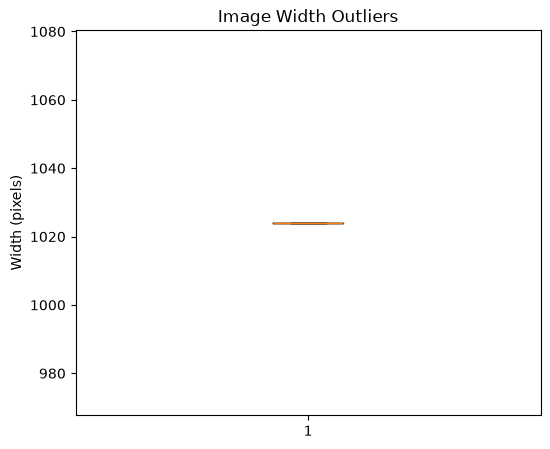

In [8]:
plt.figure(figsize=(6, 5))

plt.boxplot(
    image_df["width"]
)

plt.title("Image Width Outliers")
plt.ylabel("Width (pixels)")

plt.show()

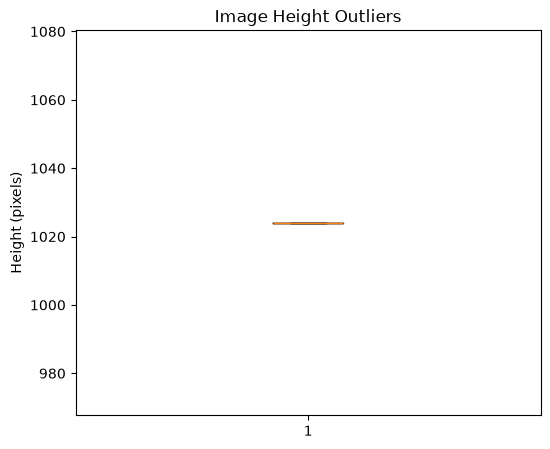

In [9]:
plt.figure(figsize=(6, 5))

plt.boxplot(
    image_df["height"]
)

plt.title("Image Height Outliers")
plt.ylabel("Height (pixels)")

plt.show()

In [10]:
bbox_df = create_bounding_box_dataframe(
    labels
)

bbox_df.head()

,patient_ids,x,y,width,height,area,aspect_ratio,center_x,center_y
0,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,80727.0,0.562005,370.5,341.5
1,00436515-870c-4b36-a041-de91049b9ab4,562.0,152.0,256.0,453.0,115968.0,0.565121,690.0,378.5
2,00704310-78a8-4b38-8475-49f4573b2dbb,323.0,577.0,160.0,104.0,16640.0,1.538462,403.0,629.0
3,00704310-78a8-4b38-8475-49f4573b2dbb,695.0,575.0,162.0,137.0,22194.0,1.182482,776.0,643.5
4,00aecb01-a116-45a2-956c-08d2fa55433f,288.0,322.0,94.0,135.0,12690.0,0.696296,335.0,389.5


In [11]:
bbox_outliers = detect_bbox_outliers(
    bbox_df
)

print(
    "Large bounding box outliers:",
    len(bbox_outliers)
)

bbox_outliers.head(10)

Large bounding box outliers: 196


,patient_ids,x,y,width,height,area,aspect_ratio,center_x,center_y
93,05d4d725-02a2-4c90-8ef8-463217889ba8,110.0,78.0,338.0,675.0,228150.0,0.500741,279.0,415.5
94,05d4d725-02a2-4c90-8ef8-463217889ba8,518.0,123.0,381.0,715.0,272415.0,0.532867,708.5,480.5
98,05eebe4c-bca2-40d4-bb20-54fc60e2bcea,529.0,139.0,371.0,577.0,214067.0,0.642981,714.5,427.5
99,05fb0374-ab2d-4cf4-bb36-ce56fb2c28a5,179.0,230.0,360.0,597.0,214920.0,0.603015,359.0,528.5
101,05fe7d73-5c8c-4349-88c4-2071a00d6d81,6.0,176.0,367.0,575.0,211025.0,0.638261,189.5,463.5
102,05fe7d73-5c8c-4349-88c4-2071a00d6d81,459.0,246.0,351.0,645.0,226395.0,0.544186,634.5,568.5
103,06089341-a69b-4777-817b-041be894b436,530.0,114.0,341.0,736.0,250976.0,0.463315,700.5,482.0
104,06089341-a69b-4777-817b-041be894b436,158.0,115.0,307.0,722.0,221654.0,0.425208,311.5,476.0
106,061664a4-6a23-4cb2-a0da-0c5712b6e0a6,629.0,124.0,369.0,624.0,230256.0,0.591346,813.5,436.0
116,06250f9d-5ad9-44ca-9283-dbf787e2ad22,460.0,243.0,380.0,574.0,218120.0,0.662021,650.0,530.0


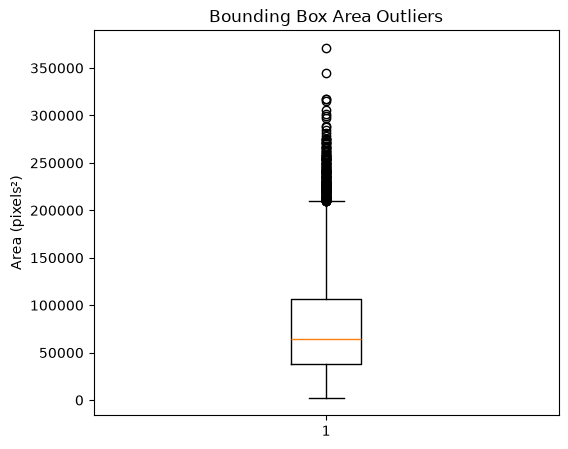

In [12]:
plt.figure(figsize=(6, 5))

plt.boxplot(
    bbox_df["area"]
)

plt.title("Bounding Box Area Outliers")
plt.ylabel("Area (pixels²)")

plt.show()

In [13]:
metadata_df = analyze_metadata(
    image_dir=image_dir,
    sample_size=1000,
    random_state=42
)

missing_metadata = detect_missing_metadata(
    metadata_df
)

missing_metadata

,missing_count,missing_percentage
patient_id,0,0.0
age,0,0.0
sex,0,0.0
view_position,0,0.0
pixel_spacing_x,0,0.0
pixel_spacing_y,0,0.0
manufacturer,0,0.0
modality,0,0.0


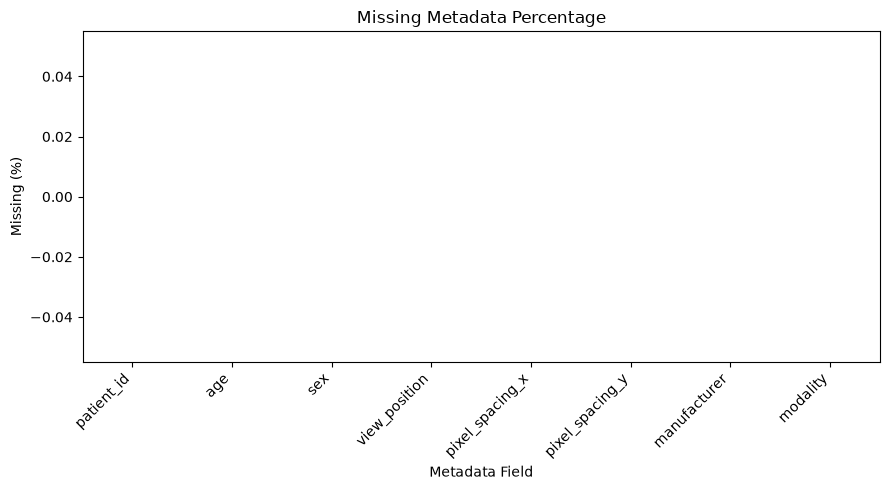

In [14]:
missing_metadata[
    "missing_percentage"
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Missing Metadata Percentage"
)

plt.xlabel("Metadata Field")
plt.ylabel("Missing (%)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [15]:
integrity_df = check_dicom_integrity(
    image_dir=image_dir,
    sample_size=1000,
    random_state=42
)

integrity_df.head()

,patient_ids,path,valid,error
0,8a5cff4d-53d2-4a42-94da-e4b3f2008b1d,..\data\raw\rsna-pneumonia-detection-challenge...,True,None
1,eefe766c-7628-48a6-be6f-f464945b06da,..\data\raw\rsna-pneumonia-detection-challenge...,True,None
2,682bd80b-cd68-4e23-be69-e50c1e5a2617,..\data\raw\rsna-pneumonia-detection-challenge...,True,None
3,8d5e12b0-44f7-4dc3-ad34-214c17045a6a,..\data\raw\rsna-pneumonia-detection-challenge...,True,None
4,a3dd7d4a-87a2-49be-b5f5-cb35b386bdd9,..\data\raw\rsna-pneumonia-detection-challenge...,True,None


In [16]:
print(
    "Valid:",
    integrity_df["valid"].sum()
)

print(
    "Invalid:",
    (~integrity_df["valid"]).sum()
)

Valid: 1000
Invalid: 0


In [17]:
integrity_df[
    integrity_df["valid"] == False
]

,patient_ids,path,valid,error


In [18]:
blank_df = detect_blank_images(
    image_dir=image_dir,
    sample_size=1000,
    random_state=42
)

blank_df.head()

,patient_ids,std_intensity,is_blank
0,8a5cff4d-53d2-4a42-94da-e4b3f2008b1d,54.402111,False
1,eefe766c-7628-48a6-be6f-f464945b06da,49.119350,False
2,682bd80b-cd68-4e23-be69-e50c1e5a2617,59.654545,False
3,8d5e12b0-44f7-4dc3-ad34-214c17045a6a,61.356621,False
4,a3dd7d4a-87a2-49be-b5f5-cb35b386bdd9,63.318375,False


In [19]:
print(
    "Potential blank images:",
    blank_df["is_blank"].sum()
)

Potential blank images: 0


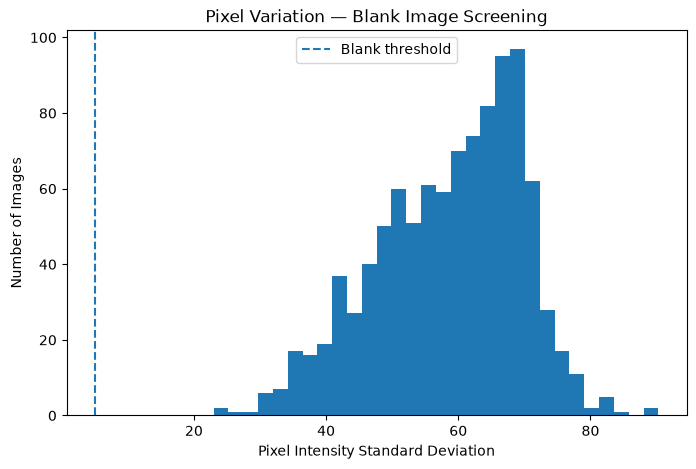

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(
    blank_df["std_intensity"].dropna(),
    bins=30
)

plt.axvline(
    5.0,
    linestyle="--",
    label="Blank threshold"
)

plt.title(
    "Pixel Variation — Blank Image Screening"
)

plt.xlabel(
    "Pixel Intensity Standard Deviation"
)

plt.ylabel(
    "Number of Images"
)

plt.legend()

plt.show()

In [21]:
from src.data.dicom_loader import load_dicom

In [23]:
potential_blank_ids = blank_df[
    blank_df["is_blank"]
]["patient_ids"].tolist()

print(
    "Potential blank images:",
    len(potential_blank_ids)
)

Potential blank images: 0


In [24]:
print(
    "===== OUTLIER SUMMARY ====="
)

print(
    "Width outliers:",
    len(
        dimension_outliers["width"]["outliers"]
    )
)

print(
    "Height outliers:",
    len(
        dimension_outliers["height"]["outliers"]
    )
)

print(
    "Large bounding-box outliers:",
    len(bbox_outliers)
)

print(
    "Potential blank images:",
    blank_df["is_blank"].sum()
)

print(
    "Invalid DICOMs in sample:",
    (~integrity_df["valid"]).sum()
)

===== OUTLIER SUMMARY =====
Width outliers: 0
Height outliers: 0
Large bounding-box outliers: 196
Potential blank images: 0
Invalid DICOMs in sample: 0
